You are a data analyst working for a tech company closely monitoring the AI tools market. You want to understand the evolving popularity of three major AI tools, ChatGPT, Gemini, and Microsoft Copilot, and identify which tool is gaining the most traction and how they compare over time.


<img src="ai_tools.jpg" align="center"/>

You'll work with real-world time series data that captures the global interest in these tools over several weeks. Your goal is to analyze this data, uncover patterns, and provide actionable insights to help your company make informed decisions. This might include determining where to focus marketing efforts, predicting future trends, or identifying potential areas for improvement.

Are you ready to help your company stay ahead of the curve in the competitive AI tools market? Let's get started!

### The Data

The Google Trends data is available as a CSV file `ai_tools_comparison.csv`.
The data contains the number of worldwide searches for chatGpt, Gemini, and Microsoft Copilot over the past 12 months as of September 2024. 
<!--- Link to query: https://trends.google.com/trends/explore?q=chatgpt,gemini,%2Fg%2F11tsqm45vd&hl=en-US -->

In [55]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data
trends = pd.read_csv('ai_tools_comparison.csv')

# Inspect the data
trends.head()

,week,chatgpt,gemini,microsoft_copilot
0,2023-08-27,56,3,1
1,2023-09-03,56,3,1
2,2023-09-10,63,3,1
3,2023-09-17,64,3,1
4,2023-09-24,66,3,1


In [56]:
# Start coding here
# Use as many cells as you need

trends['week'] = pd.to_datetime(trends['week'])

tools = ['chatgpt', 'gemini', 'microsoft_copilot']
growth = trends[tools].iloc[-1] - trends[tools].iloc[0]
print(growth)
print((trends[tools].diff() > 0).mean())

most_consistent_tool = "ChatGPT"

chatgpt              21
gemini               11
microsoft_copilot     2
dtype: int64
chatgpt              0.518519
gemini               0.277778
microsoft_copilot    0.222222
dtype: float64


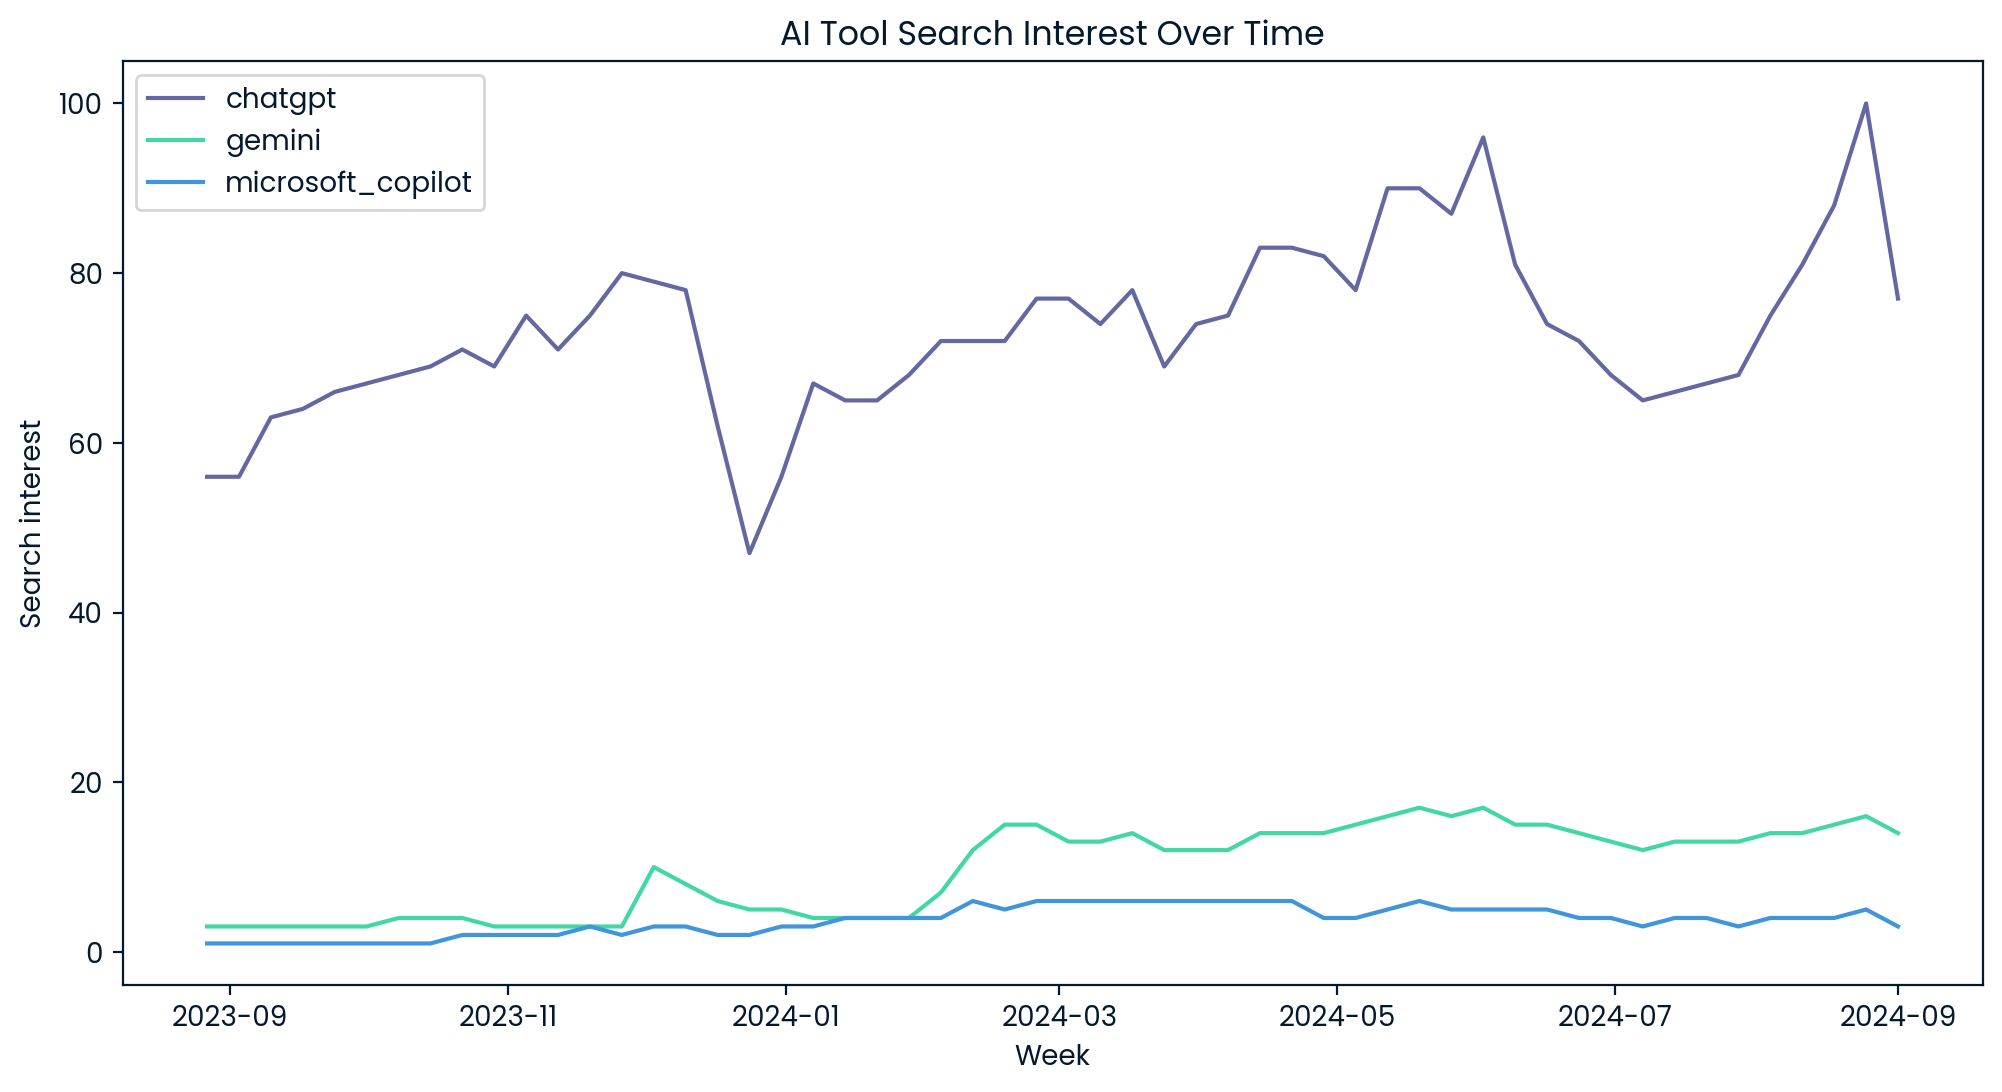

December 2023


In [57]:
plt.figure(figsize=(12, 6))
for tool in tools:
    plt.plot(trends['week'], trends[tool], label=tool)
plt.xlabel('Week')
plt.ylabel('Search interest')
plt.title('AI Tool Search Interest Over Time')
plt.legend()
plt.show()

low_idx = trends['chatgpt'].idxmin()
gpt_dip = trends.loc[low_idx, 'week'].strftime('%B %Y')
print(gpt_dip)

In [58]:
trends['month'] = trends['week'].dt.month_name()
monthly_avg = trends.groupby('month')[tools].mean()
monthly_avg['overall'] = monthly_avg[tools].mean(axis=1)
print(monthly_avg.sort_values('overall', ascending=False))

best_month = monthly_avg['overall'].idxmax()
print(best_month)

           chatgpt  gemini  microsoft_copilot    overall
month                                                   
May          86.25   16.00               5.00  35.750000
April        80.75   13.50               5.50  33.250000
June         78.20   14.80               4.60  32.533333
August       80.00   12.40               3.60  32.000000
March        74.40   12.80               6.00  31.066667
February     73.25   12.25               5.25  30.250000
July         66.50   12.75               3.50  27.583333
November     75.25    3.00               2.25  26.833333
January      66.25    4.00               3.75  24.666667
December     64.40    6.80               2.60  24.600000
October      68.80    3.60               1.40  24.600000
September    65.20    5.20               1.40  23.933333
May
